# Analysis and plotting of the final benchmark results

In [1]:
import sys
sys.path.insert(0, '/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/scripts/project_utils/')

import numpy as np
import pandas as pd
import scipy
from scipy.cluster.hierarchy import linkage, leaves_list
import seaborn as sns
import glob
import matplotlib.pyplot as plt

from bs4 import BeautifulSoup
import json
import colorcet as cc
import re

import matplotlib.font_manager as font_manager
from matplotlib.colors import Normalize, LinearSegmentedColormap
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

font_manager.fontManager.addfont('/ubc/cs/research/beaver/projects/yinian/fonts/arial.ttf')
prop = font_manager.FontProperties(fname='/ubc/cs/research/beaver/projects/yinian/fonts/arial.ttf')

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = prop.get_name()

font_manager.fontManager.addfont('/ubc/cs/research/beaver/projects/yinian/fonts/arialbd.ttf')
bold_prop = font_manager.FontProperties(fname='/ubc/cs/research/beaver/projects/yinian/fonts/arialbd.ttf')

from analysis_helpers import *

/ubc/cs/research/beaver/projects/yinian/miniconda3/envs/scmetrics/lib/python3.10/site-packages/louvain/__init__.py:54: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound


In [2]:
MAP = NAME_MAP | {
    'ccaoptuna': 'CCA-Optim',
    'scanoramaoptuna': 'Scanorama-Optim',
    'scvioptuna': 'scVI-Optim',
    'ligeroptuna': 'LIGER-Optim',
    'mnnoptuna': 'MNN-Optim',
    'harmonyoptuna': 'Harmony-Optim',
    'scphereoptuna': 'scPhere-Optim',
    'rpcaoptuna': "RPCA-Optim",
    'scanvioptuna': 'scANVI-Optim',
    'ocatoptuna': 'OCAT-Optim',
    'portaloptuna': "Portal-Optim",
    'scetmoptuna': 'scETM-Optim',
    'respanoptuna': "ResPAN-Optim",
    'sccobraoptuna': "scCobra-Optim",
    'imapoptuna': 'iMAP-Optim',
    'saucieoptuna': 'SAUCIE-Optim',
    'sysvioptuna': "sysVI-Optim",
    'insctoptuna': "INSCT-Optim",
    'sccraftoptuna': "scCRAFT-Optim",
    'scdreameroptuna': "scDREAMER-Optim",
    'scalexoptuna': 'SCALEX-Optim',
    'simbaoptuna': "SIMBA-Optim"
}

## Aggregate all the benchmarking data together, including re-runs and rescues

In [3]:
# Load the HTML file
def load_html(file_path):
    with open(file_path, 'r') as f:
        html_content = f.read()

    soup = BeautifulSoup(html_content, 'html.parser')
    script_tags = soup.find_all('script')

    task_data = None
    for tag in script_tags:
        if tag.string and 'window.data =' in tag.string:
            match = re.search(r'window\.data\s*=\s*(\{.*?\});', tag.string, re.DOTALL)
            if match:
                json_text = match.group(1)
                json_text = re.sub(r'\\(?!["\\/bfnrtu])', r'\\\\', json_text)
                task_data = json.loads(json_text)
                break

    if task_data and 'trace' in task_data:
        df = pd.DataFrame(task_data['trace'])
        result_df = df[['name', 'workdir', 'status', 'peak_rss', 'duration']]
        return result_df
    else:
        print("Could not find task data in the HTML file.")
        return None

In [4]:
runs = pd.read_csv('../_nf-trace/final_benchmarking_cpu_methods/execution_trace.txt', sep='\t')

In [42]:
runs = runs[runs.name.str.contains('METRIC')]

In [43]:
vals = []
for _, row in runs.iterrows():
    d = find_dir(row['hash'], '/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/work/final_benchmarking/cpu_methods_test/')
    f = glob.glob(str(d) + '/*.csv')[0]
    vals.append(pd.read_csv(f))

In [7]:
df = load_html('../_nf-trace/final_benchmarking_cpu_methods/execution_report.html')

In [8]:
df = df[df.status != 'FAILED']

In [9]:
df = df[df['name'].str.contains("METRIC")]

In [10]:
vals = []

for _, row in df.iterrows():
    vals.append(pd.read_csv(glob.glob(row['workdir'] + '/*.csv')[0]))

In [11]:
metrics = pd.concat(vals)

In [12]:
gedi = pd.read_csv('../results/final_benchmark/cpu_methods_gedi/metrics/all-metrics.csv')

In [13]:
tabula = pd.read_csv('../results/final_benchmark/cpu_methods_tabula_sapiens/metrics/all-metrics.csv')

In [14]:
metrics = pd.concat([metrics,gedi,tabula])

In [15]:
metrics.to_csv('../results/final_benchmark/cpu_methods/metrics/all-metrics.csv', index=False)

In [ ]:
ligeroptuna = pd.concat([pd.read_csv(d + '/ligeroptuna-1/metrics.csv') for d in glob.glob('../results/final_benchmark/liger_optuna/metrics/*')])

In [18]:
ligeroptuna.to_csv('../results/final_benchmark/liger_optuna/metrics/all_metrics.csv', index=False)

In [19]:
# A bunch of rescued re-runs
base = '../work/final_benchmarking/'
add = pd.concat([
    pd.read_csv(glob.glob(base + 'cpu_methods_test/04/95bc3bfd8913a9dfd55364d4268fb2/*.csv')[0]),
    pd.read_csv(glob.glob(base + 'gpu_methods/80/728554ac02bf9ccebe0c98405db434/*.csv')[0]),
    pd.read_csv(glob.glob(base + 'gpu_methods/db/8f169a98c07be379c7bc88bc92d143/*.csv')[0]),
    pd.read_csv(glob.glob(base + 'cpu_methods_test/00/d5bddb509c8b9c19b4a77f6ea62807/*.csv')[0]),
    pd.read_csv(glob.glob(base + 'llm_methods/3c/67bf77eff9de2aaa14160cf8f02bfa/*.csv')[0]),
    pd.read_csv(glob.glob(base + 'cpu_methods_gedi/42/bb526ebe7817dd7f471f5184b3a682/*.csv')[0]),
    pd.read_csv(glob.glob(base + 'gpu_methods/33/fa66e36a56e80a3c8e4fbb3855e425/*.csv')[0]),
    pd.read_csv(glob.glob(base + 'cpu_methods_test/5b/d5aa47e1a6a93fe677b9f4b4df2f1f/*.csv')[0]),
    pd.read_csv(glob.glob(base + 'cpu_methods_test/13/eb968a0ff0085444d4383ad0cae8af/*.csv')[0]),
    pd.read_csv(glob.glob(base + 'cpu_methods_gedi/00/a27e4700a895a597df35f7746ded42/*.csv')[0]),
    pd.read_csv(glob.glob(base + 'gpu_methods/0d/09d6350d7b8991ce9bef422c69fdf2/*.csv')[0]),
    pd.read_csv(glob.glob(base + 'gpu_methods/69/4365f2da9ffcc7e6536296f185b934/*.csv')[0]),
    pd.read_csv(glob.glob(base + 'llm_methods/03/97403719eb09c3ae2e8b8a8e5dcd59/*.csv')[0]),
    pd.read_csv(glob.glob(base + 'cpu_methods_test/36/35ef09a51b4ed5d3da201951226ac8/*.csv')[0]),
    pd.read_csv(glob.glob(base + 'llm_methods/09/947bb96c840db9689f194e029f10d3/*.csv')[0]),
    pd.read_csv(glob.glob(base + 'cpu_methods_test/08/05506ebe856e13e486b151a4be281b/*.csv')[0]),
    pd.read_csv(glob.glob(base + 'gpu_methods/4e/214d2f48d5aa9c05ce1c69a51b2f72/*.csv')[0]),
    pd.read_csv(glob.glob(base + 'gpu_methods/00/9c1598356466ed3b76bbe289610df8/*.csv')[0]),
    pd.read_csv(glob.glob(base + 'gpu_methods/c1/2df1b5cd5e32b3919f9e52ec4a6a96/*.csv')[0]),
    pd.read_csv(glob.glob(base + 'gpu_methods/f9/e6f5171ef6297d93ff25598e075868/*.csv')[0]),
    pd.read_csv(glob.glob(base + 'cpu_methods_gedi/a0/1c06b1422dbf87e8bc446b945120c4/*.csv')[0]),
    pd.read_csv(glob.glob(base + 'llm_methods/01/4a3f27155162315b62dc83330c7078/*.csv')[0]),
    pd.read_csv(glob.glob(base + 'llm_methods/00/abeb637ceba222b20c1c3a87ecc60e/*.csv')[0]),
    pd.read_csv(glob.glob(base + 'llm_methods_scprint/04/493d48421c9890d1a2d885e4802887/*.csv')[0]),
    pd.read_csv(glob.glob(base + 'gpu_methods_tabula/60/85ddbf4188759157f18370ab862822/*.csv')[0])
])


In [20]:
add.to_csv('../results/final_benchmark/rescued.csv', index=False)

## Benchmarking figures for new data

Data file: `../results/source_data/final_benchmark_new_data.csv`
### Overall figure

In [5]:
benchmark = pd.concat([
    pd.read_csv('../results/final_benchmark/cpu_methods/metrics/all-metrics.csv'),
    pd.read_csv('../results/final_benchmark/cpu_methods_gedi/metrics/all-metrics.csv'),
    pd.read_csv('../results/final_benchmark/cpu_methods_tabula_sapiens/metrics/all-metrics.csv'),
    pd.read_csv('../results/final_benchmark/gpu_methods/metrics/all-metrics.csv'),
    pd.read_csv('../results/final_benchmark/gpu_methods_cyclone/metrics/all_metrics.csv'),
    pd.read_csv('../results/final_benchmark/gpu_methods_tabula/metrics/all-metrics.csv'),
    pd.read_csv('../results/final_benchmark/llm_methods/metrics/all-metrics.csv'),
    pd.read_csv('../results/final_benchmark/llm_methods_scprint/metrics/all-metrics.csv'),
    pd.read_csv('../results/final_benchmark/cpu_methods_cca_rescue/metrics/all-metrics.csv'),
    pd.read_csv('../results/final_benchmark/gpu_methods_scalign/metrics/all-metrics.csv'),
    pd.read_csv('../results/final_benchmark/rescued.csv')
])

In [6]:
df_opt = pd.concat([
    pd.read_csv('../results/final_benchmark/scvi_optuna/metrics/all-metrics.csv'),
    pd.read_csv('../results/final_benchmark/scphere_optuna/metrics/all-metrics.csv'),
    pd.read_csv('../results/final_benchmark/harmony_optuna/metrics/all-metrics.csv'),
    pd.read_csv('../results/final_benchmark/scanorama_optuna/metrics/all-metrics.csv'),
    pd.read_csv('../results/final_benchmark/liger_optuna/metrics/all_metrics.csv'),
    pd.read_csv('../results/final_benchmark/cca_optuna/metrics/all-metrics.csv'),
    pd.read_csv('../results/final_benchmark/cca_optuna_rescue/metrics/all-metrics.csv'),
    pd.read_csv('../results/final_benchmark/mnn_optuna/metrics/all-metrics.csv'),
    pd.read_csv('../results/final_benchmark/portal_optuna/metrics/all-metrics.csv'),
    pd.read_csv('../results/final_benchmark/ocat_optuna/metrics/all-metrics.csv'),
    pd.read_csv('../results/final_benchmark/respan_optuna/metrics/all-metrics.csv'),
    pd.read_csv('../results/final_benchmark/scetm_optuna/metrics/all-metrics.csv'),
    pd.read_csv('../results/final_benchmark/scanvi_optuna/metrics/all-metrics.csv'),
    pd.read_csv('../results/final_benchmark/rpca_optuna/metrics/all-metrics.csv'),
    pd.read_csv('../results/final_benchmark/imap_optuna/metrics/all-metrics.csv'),
    pd.read_csv('../results/final_benchmark/sccobra_optuna/metrics/all-metrics.csv'),
    pd.read_csv('../results/final_benchmark/saucie_optuna/metrics/all-metrics.csv'),
    pd.read_csv('../results/final_benchmark/sysvi_optuna/metrics/all-metrics.csv'),
    pd.read_csv('../results/final_benchmark/insct_optuna/metrics/all-metrics.csv'),
    pd.read_csv('../results/final_benchmark/scalex_optuna/metrics/all-metrics.csv'),
    pd.read_csv('../results/final_benchmark/scdreamer_optuna/metrics/all-metrics.csv'),
    pd.read_csv('../results/final_benchmark/sccraft_optuna/metrics/all-metrics.csv'),
    pd.read_csv('../results/final_benchmark/simba_optuna/metrics/all-metrics.csv')
])

In [7]:
df = pd.concat([benchmark, df_opt])
df = df.drop_duplicates(subset=['Dataset', "Integration", "Metric"], keep='last')
df = df.pivot(index=['Dataset', 'Integration'], columns=['Metric'], values='Value').reset_index()

In [8]:
df['BIO'] = df[['BAMI', 'BRAS', 'ISOLISI', 'SCGRAPHM']].mean(axis=1, skipna=True)
df['BATCH'] = df[['CPCR', 'KBET', 'BRAS']].mean(axis=1, skipna=True)

In [9]:
df['OVERALL'] = df['BIO'] * .6 + df['BATCH'] * .4

In [13]:
df.to_csv('../results/spreadsheets/final_benchmark_new_data.csv', index=False)

In [11]:
df['Integration'] = df['Integration'].str[:-2]

In [12]:
df['Integration'] = df['Integration'].replace(MAP)

In [14]:
df['Dataset'].unique()

array(['gtex_v9', 'haniffa_covid_2samples', 'haniffa_covid_imbalance',
       'human_bipolar', 'human_dkd', 'human_kidney', 'human_liver',
       'human_pancreas_full', 'immune_cell_atlas', 'mouse_hsc_prog',
       'mouse_intestine', 'mouse_pancreatic_islet', 'pan_cancer_t',
       'snpatho_liver', 'tabula_sapiens', 'tabula_sapines', 'villani_dcs'],
      dtype=object)

In [15]:
df['Dataset'] = df['Dataset'].replace({
    'gtex_v9': "GTEx v9",
    'haniffa_covid_2samples': 'COVID19\n2 samples',
    'haniffa_covid_imbalance': 'COVID19\nimbalanced data',
    'human_bipolar': "Human\nbipolar",
    'human_dkd': 'Human DKD',
    'human_kidney': "Human\nkidney",
    'human_liver': 'Human\nliver',
    'human_pancreas_full': "Complete\nhuman pancreas",
    'immune_cell_atlas': 'Immune\ncell atlas',
    'mouse_hsc_prog': 'Mouse HSCs\n& progenitors',
    'mouse_intestine': "Mouse\nintestine",
    'mouse_pancreatic_islet': "Mouse\npancreatic islet",
    'pan_cancer_t': 'Pan-cancer T',
    'snpatho_liver': 'snPATHO\nliver',
    'tabula_sapiens': 'Tabula\nsapiens',
    'villani_dcs': "Villani DCs"
})

In [285]:
# {
#     'gtex_v9': "GTEx v9",
#     'haniffa_covid_2samples': 'COVID19\n2 samples',
#     'haniffa_covid_imbalance': 'COVID19\nimbalanced data',
#     'human_bipolar': "Human\nbipolar",
#     'human_dkd': 'Human DKD',
#     'human_kidney': "Human\nkidney",
#     'human_liver': 'Human\nliver',
#     'human_pancreas_full': "Complete\nhuman pancreas",
#     'immune_cell_atlas': 'Immune\ncell atlas',
#     'mouse_hsc_prog': 'Mouse HSCs\n& progenitors',
#     'mouse_intestine': "Mouse\nintestine",
#     'mouse_pancreatic_islet': "Mouse\npancreatic islet",
#     'pan_cancer_t': 'Pan-cancer T',
#     'snpatho_liver': 'snPATHO\nliver',
#     'tabula_sapiens': 'Tabula\nsapiens',
#     'villani_dcs': "Villani DCs"
# }.values()

In [16]:
wide = df.pivot(index='Integration', columns='Dataset', values=['BIO', 'BATCH', 'OVERALL'])
wide = wide.swaplevel(0, 1, axis=1)

In [17]:
wide = df.pivot(index='Integration', columns='Dataset', values="OVERALL")
 
datasets = ['Human DKD', 'snPATHO\nliver','Human\nliver', 
            'COVID19\n2 samples','COVID19\nimbalanced data', 
       'Villani DCs', 'Complete\nhuman pancreas',
        'Human\nbipolar', 'Mouse HSCs\n& progenitors', 
       'Mouse\nintestine', 'Human\nkidney', 'Pan-cancer T',
       'Immune\ncell atlas', 'GTEx v9', 'Tabula\nsapiens',
       'Mouse\npancreatic islet']

In [18]:
UNOPTIM = [
    'GTEx v9','Tabula\nsapiens', 'Immune\ncell atlas','Pan-cancer T', 'Mouse\npancreatic islet', 'Human\nkidney'
]
NONHUMAN = ['Mouse\npancreatic islet', 'Mouse HSCs\n& progenitors', 'Mouse\nintestine']
LLM = ['scPRINT', 'scGPT', 'GenePT-W', 'GeneFormer', 'LangCell', 'scMulan', "UCE"]

integrations = sorted(wide.index.unique())
wide = wide.loc[integrations, datasets]
 
n_methods = len(integrations)
n_cols = len(datasets)

In [19]:
def truncate_colormap(cmap, minval=0.05, maxval=0.85, n=256):
    return LinearSegmentedColormap.from_list(
        f"trunc({cmap.name},{minval:.2f},{maxval:.2f})",
        cmap(np.linspace(minval, maxval, n)),
    )

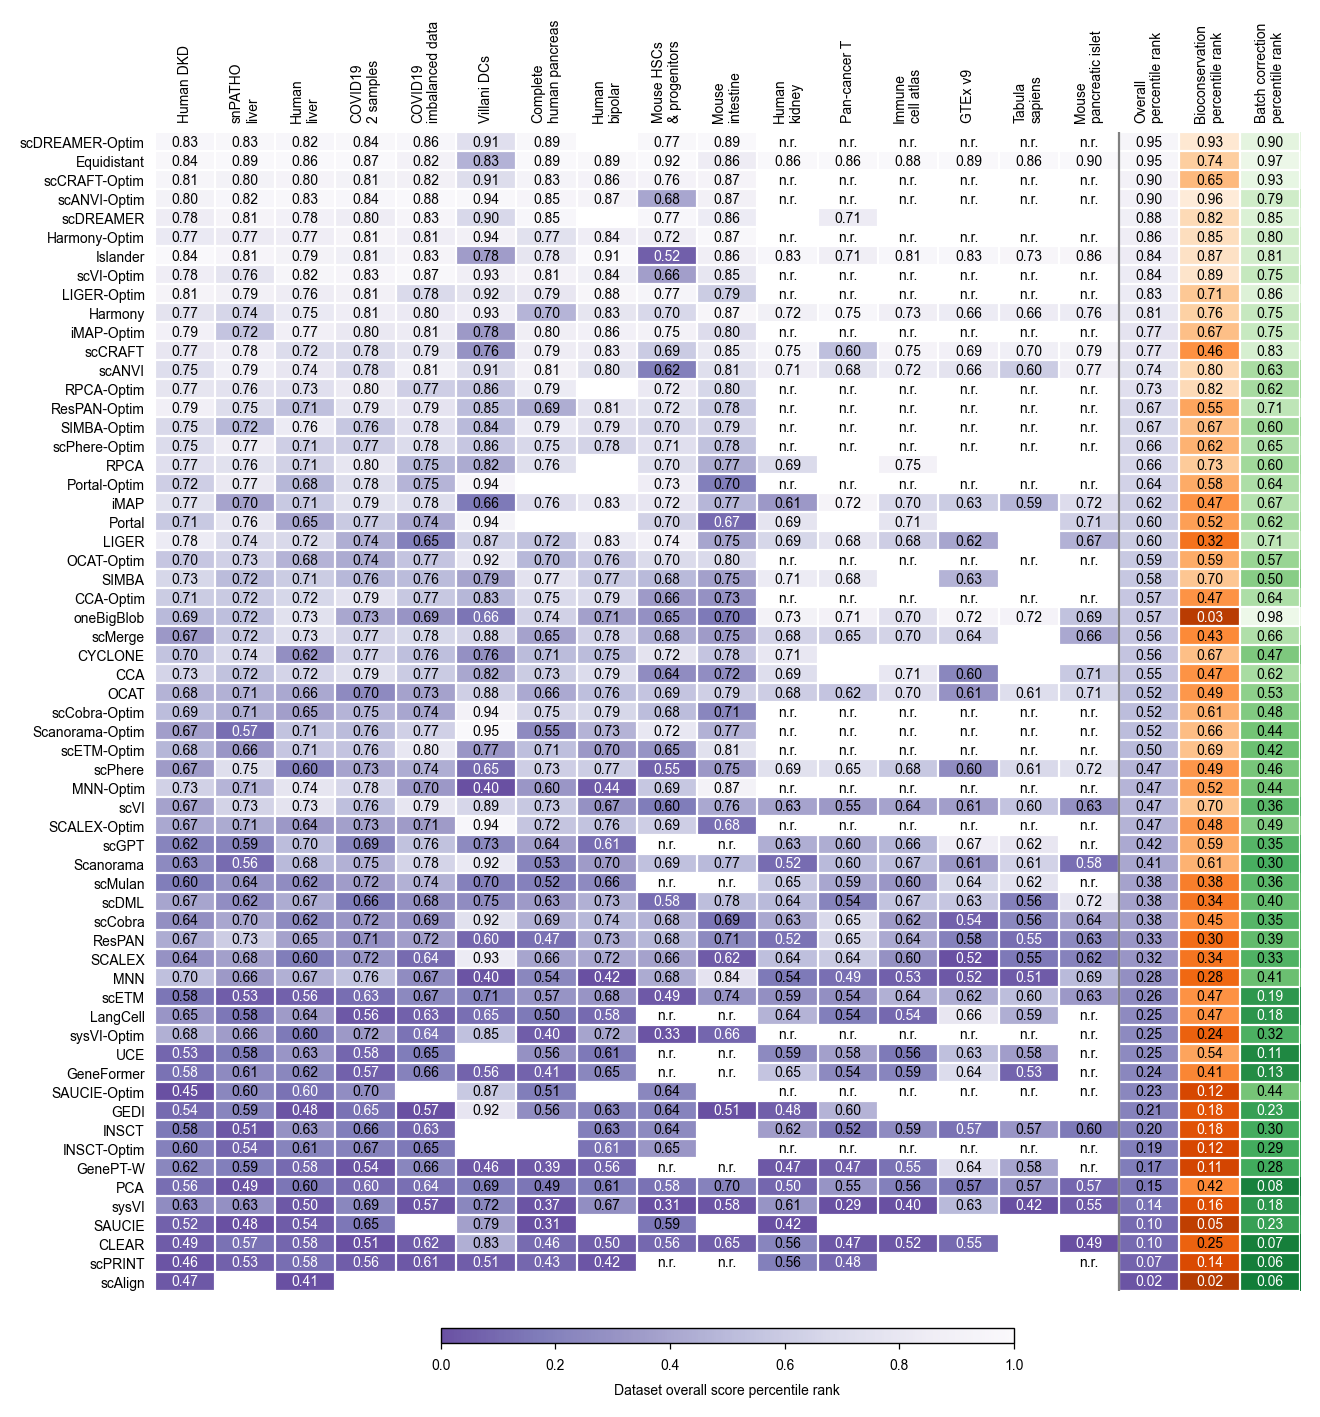

In [22]:
metrics = ['OVERALL', 'BIO', 'BATCH']
summary_labels = {'OVERALL': 'Overall\npercentile rank',
                  'BIO': 'Bioconservation\npercentile rank',
                  'BATCH': 'Batch correction\npercentile rank'}

def percentile_ranks(w):
    """Per-dataset relative rank in [0, 1] (1 = best), NaN where missing."""
    ranked = w.rank(ascending=False, method="min", axis=0)
    n_valid = w.notna().sum(axis=0)
    rel = (n_valid - ranked) / (n_valid - 1).replace(0, np.nan)
    return rel.fillna(1.0).where(w.notna())

integrations = sorted(df['Integration'].unique())
n_methods = len(integrations)
n_cols = len(datasets)

wides = {
    m: df.pivot(index='Integration', columns='Dataset', values=m).loc[integrations, datasets]
    for m in metrics
}
rel_ranks = {m: percentile_ranks(wides[m]) for m in metrics}

avg_pct = pd.DataFrame({m: rel_ranks[m].mean(axis=1, skipna=True) for m in metrics})
integrations = avg_pct['OVERALL'].sort_values(ascending=False).index.tolist()
avg_pct = avg_pct.loc[integrations]
wide = wides['OVERALL'].loc[integrations]
rel_rank = rel_ranks['OVERALL'].loc[integrations]

overall_cmap = truncate_colormap(plt.get_cmap("Purples"), 0.02, 0.75)
bio_cmap     = truncate_colormap(plt.get_cmap("Oranges"))
batch_cmap   = truncate_colormap(plt.get_cmap("Greens"))
summary_cmaps = {'OVERALL': overall_cmap, 'BIO': bio_cmap, 'BATCH': batch_cmap}

n_summary = len(metrics)
n_total = n_cols + n_summary

rgba = np.ones((n_methods, n_total, 4))
text_colors = np.full((n_methods, n_total), "black", dtype=object)

def set_cell(i, j, color):
    rgba[i, j] = color
    r, g, b, _ = color
    luminance = 0.299 * r + 0.587 * g + 0.114 * b
    text_colors[i, j] = "white" if luminance < 0.5 else "black"

for i, method in enumerate(integrations):
    for j, dset in enumerate(datasets):
        if pd.isna(wide.loc[method, dset]):
            continue
        set_cell(i, j, overall_cmap(1.0 - rel_rank.loc[method, dset]))

    for k, m in enumerate(metrics):
        val = avg_pct.loc[method, m]
        if pd.isna(val):
            continue
        set_cell(i, n_cols + k, summary_cmaps[m](1.0 - val))

fig_w = 6.7
fig_h = 7.2

with plt.rc_context({"figure.dpi": 200}):
    fig, ax = plt.subplots(figsize=(fig_w, fig_h))

    ax.imshow(rgba, aspect="auto",
              extent=(-0.5, n_total - 0.5, n_methods - 0.5, -0.5))

    for i in range(n_methods):
        for j in range(n_cols):
            score = wide.iloc[i, j]
            if pd.isna(score):
                if integrations[i].endswith('Optim') and datasets[j] in UNOPTIM:
                    ax.text(j, i, "n.r.", ha="center", va="center", fontsize=5, zorder=2)
                if integrations[i] in LLM and datasets[j] in NONHUMAN:
                    ax.text(j, i, "n.r.", ha="center", va="center", fontsize=5, zorder=2)
                continue
            ax.text(j, i, f"{score:.2f}", ha="center", va="center",
                    fontsize=5, color=text_colors[i, j], zorder=2)

    for k, m in enumerate(metrics):
        x = n_cols + k
        for i, method in enumerate(integrations):
            val = avg_pct.loc[method, m]
            ax.text(x, i, "–" if pd.isna(val) else f"{val:.2f}",
                    ha="center", va="center", fontsize=5,
                    color=text_colors[i, x], zorder=2)

    for j in range(n_total + 1):
        ax.axvline(j - 0.5, color="white", linewidth=.8, zorder=1)
    for i in range(n_methods + 1):
        ax.axhline(i - 0.5, color="white", linewidth=.8, zorder=1)

    ax.axvline(n_cols - 0.5, color="grey", linewidth=.8, zorder=3)

    percentile_cmap = overall_cmap.reversed()
    sm = ScalarMappable(norm=Normalize(vmin=0.0, vmax=1.0), cmap=percentile_cmap)
    sm.set_array([])

    cbar = fig.colorbar(
        sm, ax=ax, orientation="horizontal",
        fraction=0.03, pad=0.03, aspect=40, shrink=0.5,
    )
    cbar.set_label("Dataset overall score percentile rank", fontsize=5, labelpad=4)
    cbar.ax.tick_params(labelsize=5, length=2, width=.45)
    cbar.outline.set_linewidth(0.5)

    xlabels = datasets + [summary_labels[m] for m in metrics]
    ax.set_xticks(np.arange(n_total))
    ax.set_xticklabels(xlabels, rotation=90, fontsize=5, multialignment='left')
    ax.xaxis.set_ticks_position("top")
    ax.xaxis.set_label_position("top")
    ax.set_xlim(-0.5, n_total - 0.5)

    ax.set_yticks(np.arange(n_methods))
    ax.set_yticklabels(integrations, fontsize=5)
    ax.set_ylim(n_methods - 0.5, -0.5)

    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.tick_params(length=0)

    plt.tight_layout()
    fig.savefig("../publication_figures/new_benchmark.svg", bbox_inches="tight", dpi=300)
    plt.show()

### Extended Data Figure

In [23]:
ORDERED_INT = integrations

In [24]:
wide = df.pivot(index='Integration', columns='Dataset', values=['BIO', 'BATCH', 'OVERALL'])
wide = wide.swaplevel(0, 1, axis=1)

In [25]:
datasets = ['Human DKD', 'snPATHO\nliver', 'Human\nliver', 'COVID19\n2 samples','COVID19\nimbalanced data', 
       'Villani DCs', 'Complete\nhuman pancreas',
        'Human\nbipolar', 'Mouse HSCs\n& progenitors', 
       'Mouse\nintestine', 'Human\nkidney', 'Pan-cancer T',
       'Immune\ncell atlas', 'GTEx v9', 'Tabula\nsapiens',
       'Mouse\npancreatic islet']

integrations = ORDERED_INT

ordered_cols = [(d, m) for d in datasets for m in ['BIO', 'BATCH', 'OVERALL']]
wide = wide.loc[integrations, ordered_cols]

n_methods = len(integrations)
n_cols = len(ordered_cols)

ranked = wide.rank(ascending=False, method="min", axis=0)
n_methods = len(integrations)
rank_norm = Normalize(vmin=1, vmax=n_methods)


bio_cmap = truncate_colormap(plt.get_cmap("Oranges"))
batch_cmap = truncate_colormap(plt.get_cmap("Greens"))
overall_cmap = truncate_colormap(plt.get_cmap("Purples"), 0.02, 0.75)
metric_cmaps = {"BIO": bio_cmap, "BATCH": batch_cmap, "OVERALL": overall_cmap}

/tmp/ipykernel_1646572/3224870173.py:131: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


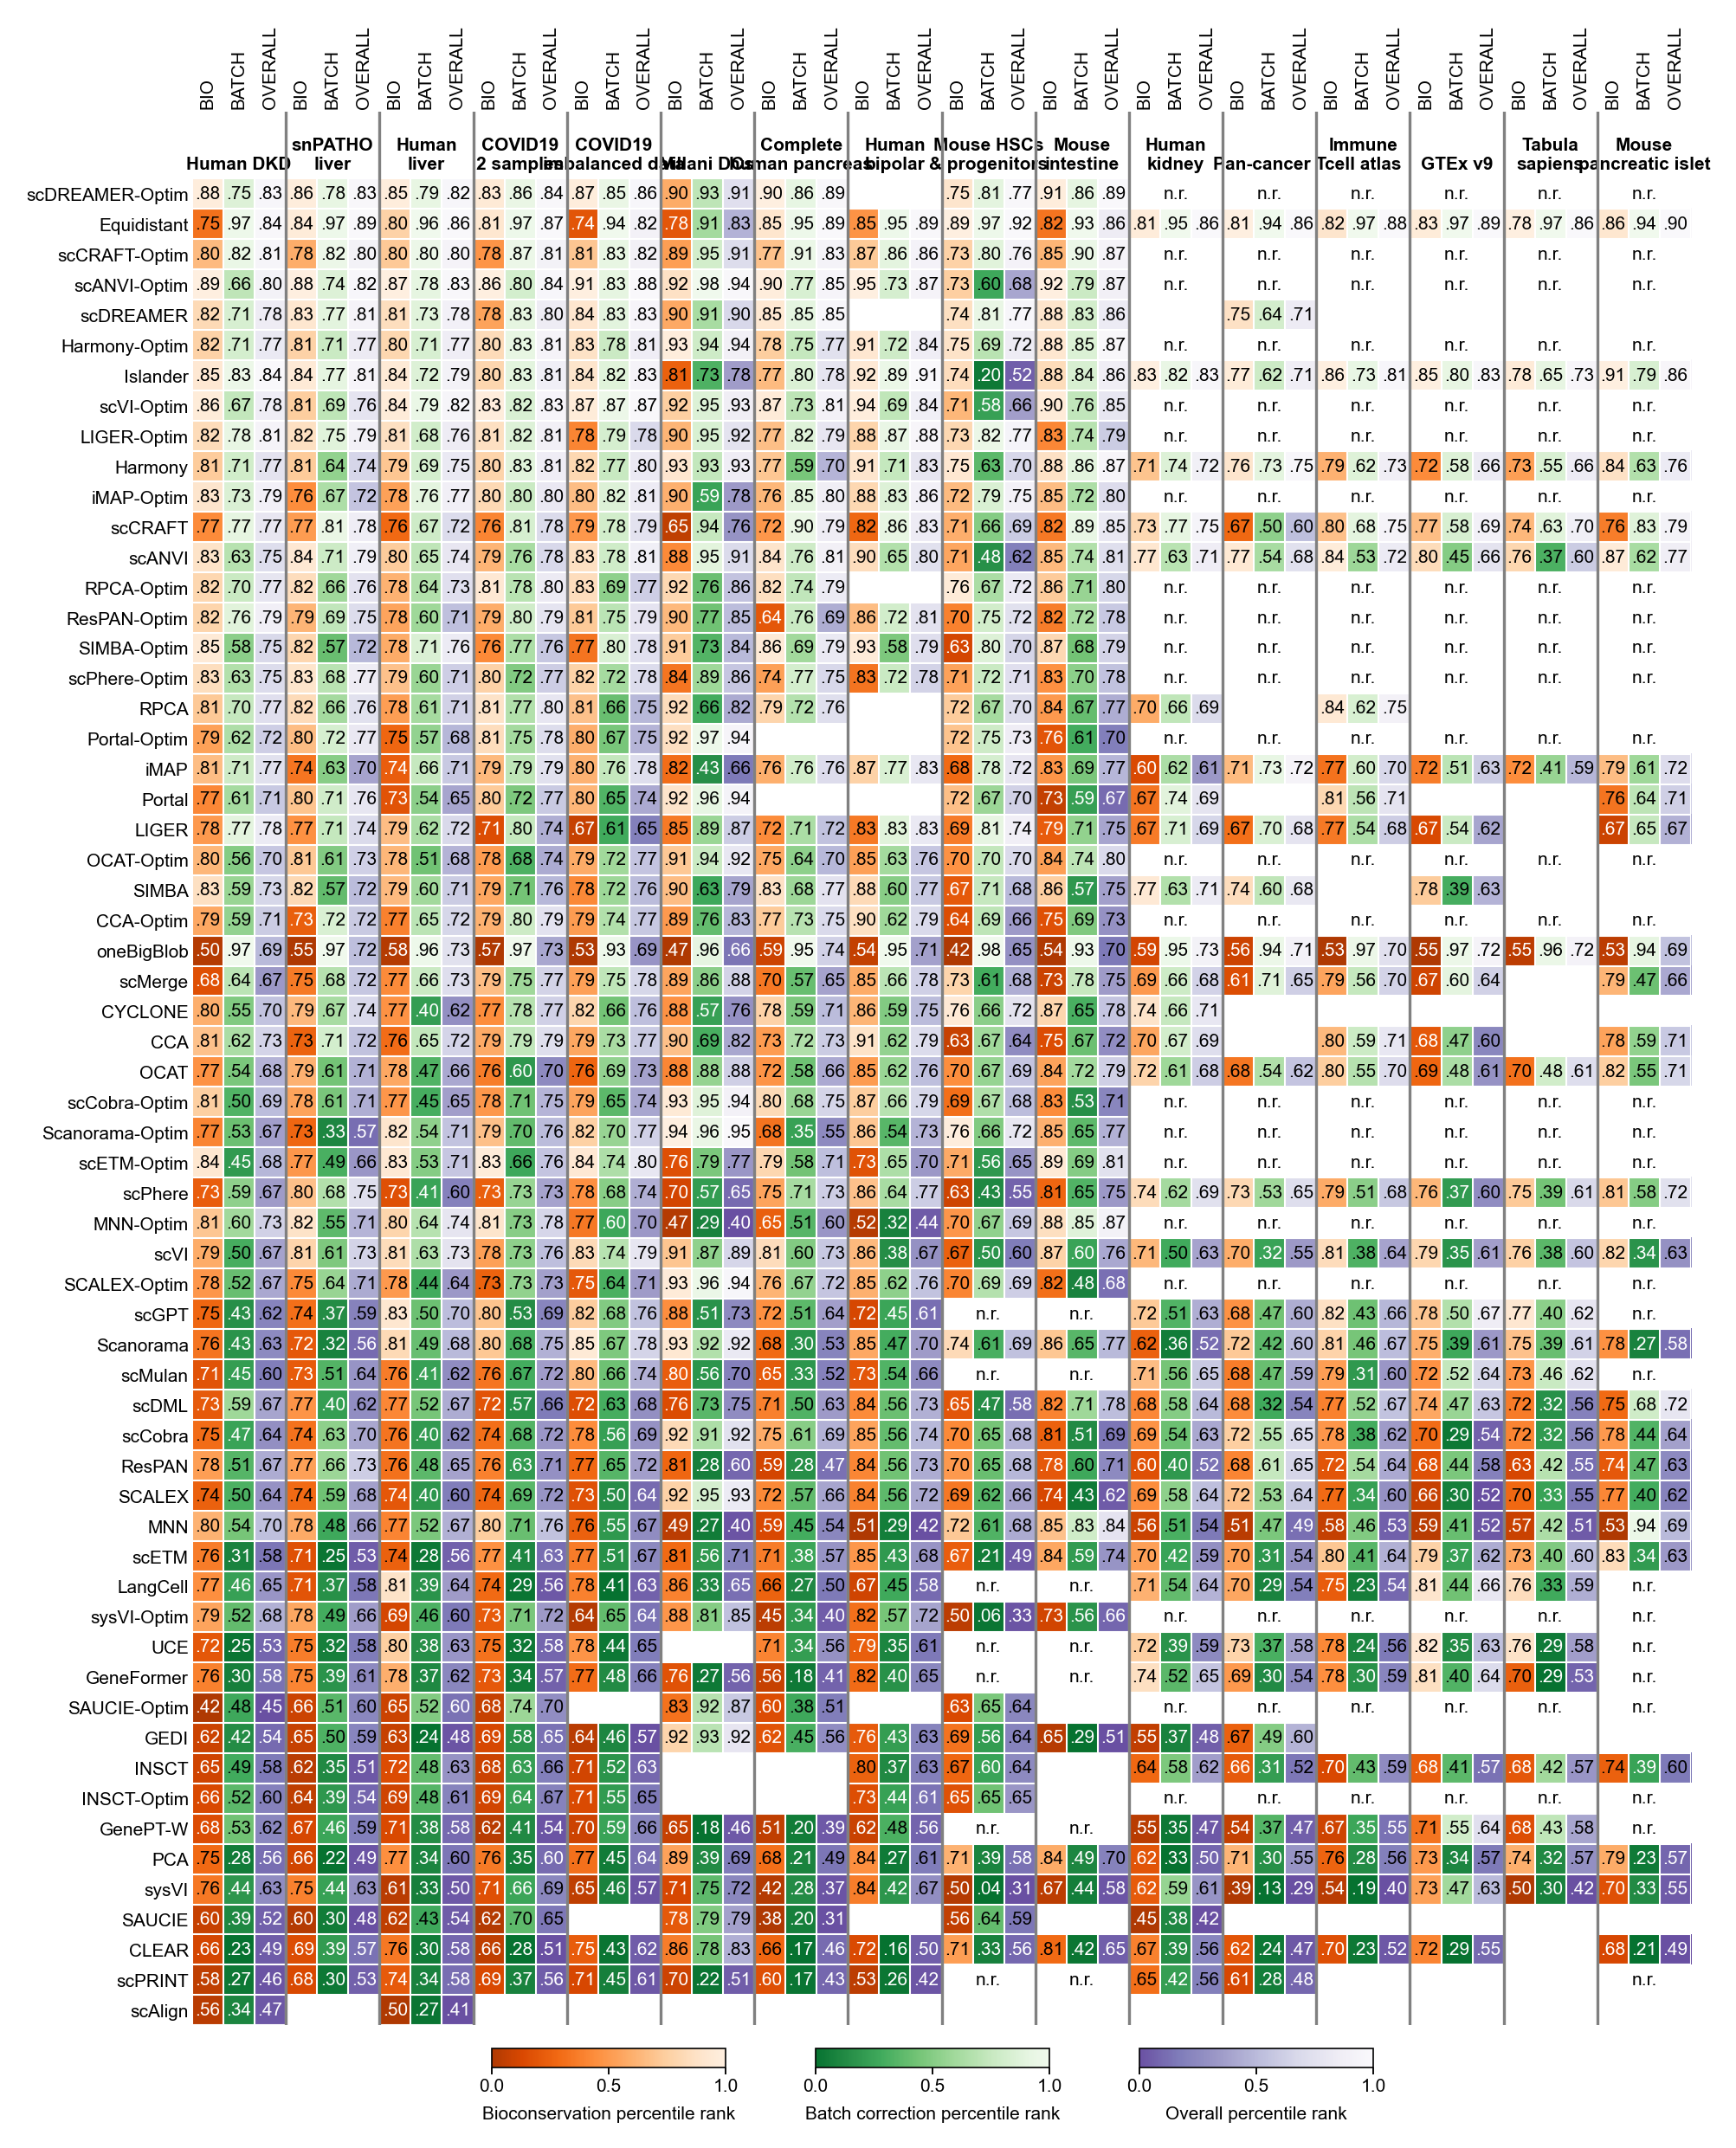

In [26]:
METRICS = ['BIO', 'BATCH', 'OVERALL']
ranked = wide.rank(ascending=False, method="min", axis=0)
n_valid = wide.notna().sum(axis=0)

rel_rank = (n_valid - ranked) / (n_valid - 1).replace(0, np.nan)
rel_rank = rel_rank.fillna(1.0).where(wide.notna())

rgba = np.ones((n_methods, n_cols, 4))  # default white (for NaNs)
text_colors = np.full((n_methods, n_cols), "black", dtype=object)

for i, method in enumerate(integrations):
    for j, (dset, metric) in enumerate(ordered_cols):
        score = wide.loc[method, (dset, metric)]
        if pd.isna(score):
            continue
        color = metric_cmaps[metric](1.0 - rel_rank.loc[method, (dset, metric)])
        rgba[i, j] = color
        r, g, b, _ = color
        luminance = 0.299 * r + 0.587 * g + 0.114 * b
        text_colors[i, j] = "white" if luminance < 0.5 else "black"

cell_w, cell_h = 0.3, 0.3
fig_w = 6.8
fig_h = 8
 
with plt.rc_context({"figure.dpi": 300}):
    fig, ax = plt.subplots(figsize=(fig_w, fig_h))

    ax.imshow(rgba, aspect="auto", extent=(-0.5, n_cols - 0.5, n_methods - 0.5, -0.5))

    for i in range(n_methods):
        for j in range(n_cols):
            score = wide.iloc[i, j]
            if pd.isna(score):
                if integrations[i].endswith('Optim') and datasets[j // 3] in UNOPTIM and j % 3 == 1:
                    ax.text(
                        j, i, "n.r.", ha="center", va="center",
                        fontsize=5, zorder=2,
                    )
                if integrations[i] in LLM and datasets[j // 3] in NONHUMAN and j % 3 == 1:
                    ax.text(
                        j, i, "n.r.", ha="center", va="center",
                        fontsize=5, zorder=2,
                    )
                continue
            ax.text(
                j, i, f"{score:.2f}".lstrip("0"), ha="center", va="center",
                fontsize=5, color=text_colors[i, j], zorder=2,
            )

    for j in range(n_cols + 1):
        ax.axvline(j - 0.5, color="white", linewidth=.5, zorder=1)
    for i in range(n_methods + 1):
        ax.axhline(i - 0.5, color="white", linewidth=.5, zorder=1)

    ax.set_xticks(np.arange(n_cols))
    ax.set_xticklabels([m for _, m in ordered_cols], rotation=90, fontsize=5)
    ax.xaxis.set_ticks_position("top")
    ax.xaxis.set_label_position("top")
    ax.set_xlim(-0.5, n_cols - 0.5)

    for d_idx, dset in enumerate(datasets):
        start = d_idx * len(METRICS)
        end = start + len(METRICS) - 1
        center = (start + end) / 2
        ax.text(
            center, -.7, dset, ha="center", va="bottom", fontsize=5,
            fontweight="bold", transform=ax.transData,
        )
        if d_idx > 0:
            ax.axvline(start - 0.5, color="grey", linewidth=.8, zorder=3)

    ax.set_yticks(np.arange(n_methods))
    ax.set_yticklabels(integrations, fontsize=5)
    ax.set_ylim(n_methods - 0.5, -2.7)

    for spine in ax.spines.values():
        spine.set_visible(False)
    
    ax.tick_params(
        axis='both', which='major', width=.45,
        length=0, labelsize=5, pad=1
    )
    
    cbar_container = inset_axes(
        ax,
        width="60%",
        height="1%",
        loc="lower center",
        bbox_to_anchor=(0.0, -0.022, 1.0, 1.0),
        bbox_transform=ax.transAxes,
        borderpad=0
    )
    cbar_container.axis("off")

    norm_01 = Normalize(vmin=0.0, vmax=1.0)
    bar_width = 0.26
    gap = 0.10

    for idx, metric in enumerate(METRICS):
        x_pos = idx * (bar_width + gap)
        cax = inset_axes(
            cbar_container,
            width=f"{bar_width * 100}%",
            height="100%",
            loc="lower left",
            bbox_to_anchor=(x_pos, 0.0, 1.0, 1.0),
            bbox_transform=cbar_container.transAxes,
            borderpad=0
        )

        cmap_rev = metric_cmaps[metric].reversed()
        sm = ScalarMappable(norm=norm_01, cmap=cmap_rev)
        sm.set_array([])

        cb = fig.colorbar(sm, cax=cax, orientation="horizontal")
        cb.solids.set_rasterized(False)
        
        if metric == 'BIO':
            title = 'Bioconservation percentile rank'
        elif metric == 'BATCH':
            title = 'Batch correction percentile rank'
        else:
            title = 'Overall percentile rank'
        cb.set_label(title, fontsize=5, labelpad=3)
        cb.set_ticks([0.0, 0.5, 1.0])
        cb.ax.tick_params(labelsize=5, length=2, pad=1, width=.45)
        cb.outline.set_linewidth(0.4)
    

    plt.tight_layout()
    # The dataset names are fixed in post
    fig.savefig("../publication_figures/bio_batch_overall.svg", bbox_inches="tight", dpi=300)
    plt.show()

### Changes in ranking

In [29]:
wide = df.pivot(index='Integration', columns='Dataset', values=['BIO', 'BATCH', 'OVERALL'])
wide = wide.swaplevel(0, 1, axis=1)

In [30]:
wide = df.pivot(index='Integration', columns='Dataset', values="OVERALL")
 
datasets = ['COVID19\n2 samples','COVID19\nimbalanced data', 'Human DKD', 
       'Villani DCs', 'snPATHO\nliver', 'Complete\nhuman pancreas',
       'Human\nliver', 'Mouse HSCs\n& progenitors', 'Human\nbipolar',
       'Mouse\nintestine']

integrations = sorted(wide.index.unique())
wide = wide.loc[integrations, datasets]

In [31]:
ranked = wide.rank(ascending=False, method="min", axis=0)
n_valid = wide.notna().sum(axis=0)

rel_rank = (n_valid - ranked) / (n_valid - 1).replace(0, np.nan)
rel_rank = rel_rank.fillna(1.0).where(wide.notna())

avg_percentile = rel_rank.mean(axis=1, skipna=True)
integrations = avg_percentile.sort_values(ascending=False).index.tolist()
avg_percentile = avg_percentile.loc[integrations]

wide = wide.loc[integrations]
ranked = ranked.loc[integrations]
rel_rank = rel_rank.loc[integrations]

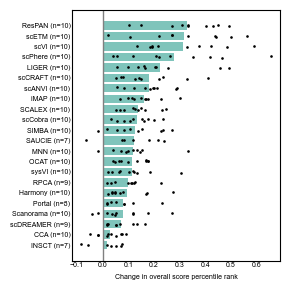

In [34]:
df = rel_rank.copy()
df.columns = [str(c).replace("\\n", " ").replace("\n", " ") for c in df.columns]

rng = np.random.default_rng(0)
jitter = 0.1

bases = [m for m in df.index if f"{m}-Optim" in df.index]
delta = pd.DataFrame(
    {b: df.loc[f"{b}-Optim"] - df.loc[b] for b in bases}
).T

delta["mean"] = delta.mean(axis=1, skipna=True)
delta["n"] = delta.drop(columns="mean").notna().sum(axis=1)
delta = delta.sort_values("mean")

plot_data = delta.drop(columns=["mean", "n"])

fig, ax = plt.subplots(figsize=(3, 3))
y = np.arange(len(plot_data))

colors = np.where(delta["mean"] >= 0, "#2a9d8f", "#e76f51")
ax.barh(y, delta["mean"], color=colors, alpha=0.6, zorder=1)
for i, (_, row) in enumerate(plot_data.iterrows()):
    vals = row.dropna().values
    ax.scatter(vals, i + rng.uniform(-jitter, jitter, size=len(vals)),
               color="k", s=.8, zorder=2)

ax.axvline(0, color="grey", lw=1)
ax.set_yticks(y)
ax.set_yticklabels([f"{m} (n={int(n)})" for m, n in zip(delta.index, delta["n"])])
ax.set_xlabel("Change in overall score percentile rank", fontsize=5)

ax.tick_params(
    axis='both', which='major', width=.45,
    length=0, labelsize=5, pad=1
)
plt.tight_layout()
plt.savefig('../publication_figures/change_in_percentile_rank.svg')
plt.show()

## Redux versions

Including runs with Optuna hyperparameter optimization

In [108]:
redux = pd.read_csv('../results/final_benchmark/recompute_old_data/metrics/all-metrics.csv')

In [109]:
df_opt = pd.concat([
    pd.read_csv('../results/final_benchmark/re_harmony_optuna/metrics/all-metrics.csv'),
    pd.read_csv('../results/final_benchmark/re_cca_optuna/metrics/all-metrics.csv'),
    pd.read_csv('../results/final_benchmark/re_scanorama_optuna//metrics/all-metrics.csv'),
    pd.read_csv('../results/final_benchmark/re_scvi_optuna/metrics/all-metrics.csv'),
    pd.read_csv('../results/final_benchmark/re_liger_optuna/metrics/all-metrics.csv'),
#     pd.read_csv('../results/final_benchmark/re_mnn_optuna/metrics/all-metrics.csv'),
#     pd.read_csv('../results/final_benchmark/re_rpca_optuna/metrics/all-metrics.csv'),
#     pd.read_csv('../results/final_benchmark/re_scanvi_optuna/metrics/all-metrics.csv'),
#     pd.read_csv('../results/final_benchmark/re_scphere_optuna/metrics/all-metrics.csv'),
#     pd.read_csv('../results/final_benchmark/re_scetm_optuna/metrics/all-metrics.csv'),
#     pd.read_csv('../results/final_benchmark/re_respan_optuna/metrics/all-metrics.csv'),
#     pd.read_csv('../results/final_benchmark/re_simba_optuna/metrics/all-metrics.csv'),
#     pd.read_csv('../results/final_benchmark/re_sysvi_optuna/metrics/all-metrics.csv'),
#     pd.read_csv('../results/final_benchmark/re_sccraft_optuna/metrics/all-metrics.csv'),
#     pd.read_csv("../results/final_benchmark/re_ocat_optuna/metrics/all-metrics.csv"),
#     pd.read_csv('../results/final_benchmark/re_imap_optuna/metrics/all-metrics.csv'),
#     pd.read_csv('../results/final_benchmark/re_imap_optuna_human_pbmc_seq_techs/metrics/all-metrics.csv'),
#     pd.read_csv('../results/final_benchmark/re_saucie_optuna/metrics/all-metrics.csv'),
#     pd.read_csv('../results/final_benchmark/re_scdreamer_optuna/metrics/all-metrics.csv'),
#     pd.read_csv('../results/final_benchmark/re_scdreamer_optuna_2/metrics/all-metrics.csv'),
#     pd.read_csv('../results/final_benchmark/re_insct_optuna/metrics/all-metrics.csv'),
#     pd.read_csv('../results/final_benchmark/re_scalex_optuna/metrics/all-metrics.csv'),
])

## Just overall plot

Data file: `../results/source_data/rebenchmark_old_data.csv`

In [120]:
df = pd.concat([redux, df_opt])
df = df.pivot(index=['Dataset', 'Integration'], columns=['Metric'], values='Value').reset_index()

In [121]:
df['BIO'] = df[['BAMI', 'BRAS', 'ISOLISI', 'SCGRAPHM', 'TRAJ']].mean(axis=1, skipna=True)
df['BATCH'] = df[['CPCR', 'KBET', 'BRAS']].mean(axis=1, skipna=True)

In [122]:
df['OVERALL'] = df['BIO'] * .6 + df['BATCH'] * .4

In [123]:
df['Integration'] = df['Integration'].str[:-2]

In [124]:
df['Integration'] = df['Integration'].replace(MAP)

In [126]:
df.to_csv('../results/spreadsheets/rebenchmark_old_data.csv', index=False)

In [115]:
df['Dataset'] = df['Dataset'].replace({
    '3_5_pbmc': "10x 3'/5'\nPBMC",
    'cellranger_versions': 'Cellranger\nversions',
    'human_adipose': 'Human\nadipose',
    'human_brain_cell_atlas': "Human brain\ncell atlas",
    'human_eoe': 'Human\nEoE',
    'human_fetal_gut': "Human\nfetal gut",
    'human_heart': 'Human\nheart',
    'human_lung': 'Human\nlung',
    'human_pancreas': "Human\npancreas",
    'human_pbmc_sequencing_techs': 'Human PBMC\nsequencing techs',
    'human_retina_organoid_tissue': "Human retina\norganoid & tissue",
    'jurkat_293t': 'Jurkat/293T',
    'macaque_retina': "Macaque\nretina",
    'mouse_cortex_sequencing_techs': 'Mouse cortex\nsequencing techs',
    'mouse_mammary': "Mouse\nmammary",
    'mouse_regulatory_T': 'Mouse\nregulatory T',
    'mouse_retina': 'Mouse\nretina',
    'neurips_bmmc': "NeurIPS\nBMMC",
    'nph_cerebellum': "NHP\ncerebellum",
    'nph_liver': "NHP liver",
    'pan_cancer_b': "Pan-cancer B",
    'pan_cancer_dc': 'Pan-cancer DC',
    'scib_sim1': 'scIB sim 1',
    'scib_sim2': 'scIB sim 2',
    'seurat_pbmc': 'Seurat PBMC',
    'tabula_muris_lung': "Tabula\nmuris lung",
    'tian_multitech': "Multitech\ncell lines"
})

In [116]:
wide = df.pivot(index='Integration', columns='Dataset', values=['BIO', 'BATCH', 'OVERALL'])
wide = wide.swaplevel(0, 1, axis=1)

In [117]:
wide = df.pivot(index='Integration', columns='Dataset', values="OVERALL")
 
# order datasets alphabetically (or set your own explicit order here)
# datasets = [
#     "10x 3'/5'\nPBMC", 'Cellranger\nversions', 'Human\nadipose', 'Human brain\ncell atlas', 'Human\nEoE',
#     'Human\nfetal gut', 'Human\nheart', 'Human\nlung', 'Human\npancreas', 'Human PBMC\nsequencing techs',
#     'Human retina\norganoid & tissue', 'NeurIPS\nBMMC','Seurat PBMC', 'Pan-cancer B', 'Pan-cancer DC',
#     'Jurkat/293T', 'Multitech\ncell lines',
#     'Mouse cortex\nsequencing techs', 'Mouse\nmammary', 'Mouse\nregulatory T', 'Mouse\nretina', 
#     'Tabula\nmuris lung', 'NHP\ncerebellum', 'NHP liver','Macaque\nretina',  'scIB sim 1', 'scIB sim 2'
# ]
datasets = [
    'Human\npancreas', 'Cellranger\nversions', 'Multitech\ncell lines',
    'Human PBMC\nsequencing techs', 'Jurkat/293T', "10x 3'/5'\nPBMC",
    'NeurIPS\nBMMC', 'Human\nlung', 'Human\nfetal gut', 'Human\nadipose',
    'scIB sim 1', 'scIB sim 2', 'Mouse\nretina', 'NHP liver', 'Macaque\nretina', 'NHP\ncerebellum',
    'Human retina\norganoid & tissue','Tabula\nmuris lung','Mouse\nmammary',
    'Mouse cortex\nsequencing techs', 'Mouse\nregulatory T', 
#     'Seurat PBMC','Human\nEoE', 'Pan-cancer B','Human\nheart', 'Pan-cancer DC', 'Human brain\ncell atlas'
]

UNOPTIM = [
    'Human brain\ncell atlas', 'Human\nEoE', 'Human\nheart',
    'Seurat PBMC', 'Pan-cancer B', 'Pan-cancer DC',
]
NONHUMAN = ['Mouse cortex\nsequencing techs', 'Mouse\nmammary', 'Mouse\nregulatory T', 'Mouse\nretina', 
    'Tabula\nmuris lung', 'NHP\ncerebellum', 'NHP liver','Macaque\nretina',  'scIB sim 1', 'scIB sim 2']
LLM = ['scPRINT', 'scGPT', 'GenePT-W', 'GeneFormer', 'LangCell', 'scMulan', "UCE"]

integrations = sorted(wide.index.unique())
wide = wide.loc[integrations, datasets]
 
n_methods = len(integrations)
n_cols = len(datasets)

In [104]:
wide.isna().sum().sort_values()

Dataset
Human\npancreas                     0
Cellranger\nversions                1
Multitech\ncell lines               1
Jurkat/293T                         2
NeurIPS\nBMMC                       2
10x 3'/5'\nPBMC                     2
Human PBMC\nsequencing techs        3
Human\nlung                         4
Human\nfetal gut                    5
Human\nadipose                      5
scIB sim 1                          7
scIB sim 2                          7
Human retina\norganoid & tissue     7
Mouse\nretina                       8
NHP\ncerebellum                     8
Macaque\nretina                     8
NHP liver                           9
Mouse\nmammary                      9
Tabula\nmuris lung                 10
Mouse cortex\nsequencing techs     12
Mouse\nregulatory T                13
dtype: int64

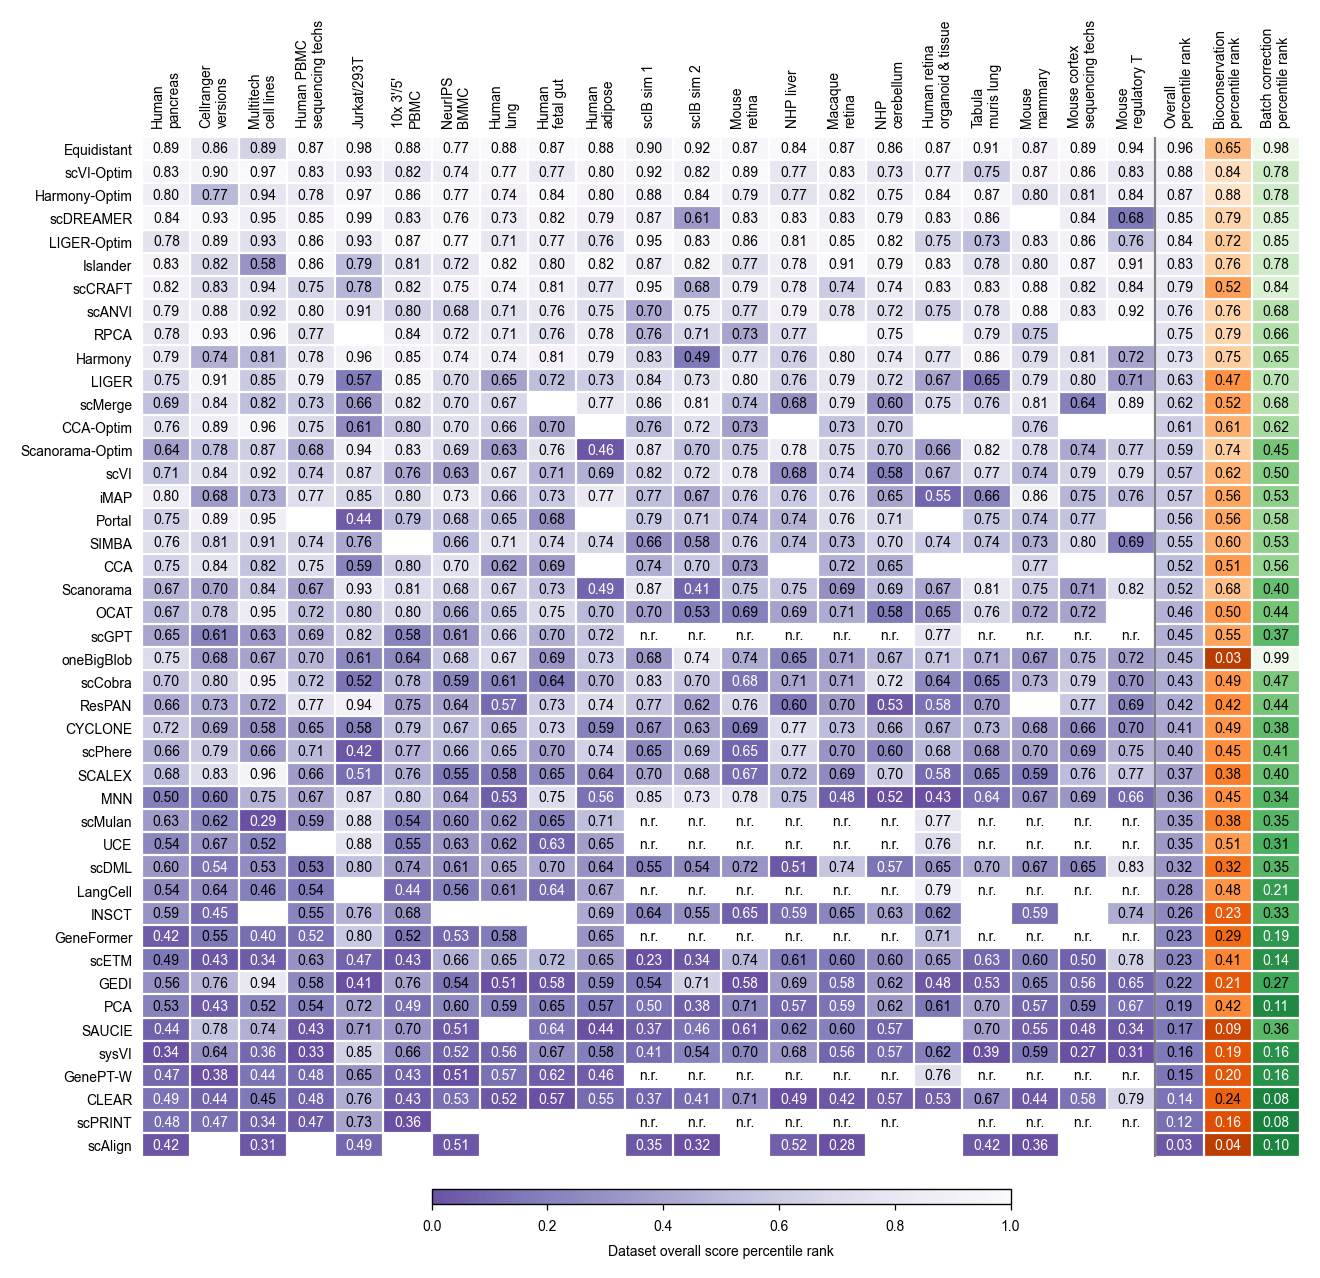

In [107]:
metrics = ['OVERALL', 'BIO', 'BATCH']
summary_labels = {'OVERALL': 'Overall\npercentile rank',
                  'BIO': 'Bioconservation\npercentile rank',
                  'BATCH': 'Batch correction\npercentile rank'}

def percentile_ranks(w):
    """Per-dataset relative rank in [0, 1] (1 = best), NaN where missing."""
    ranked = w.rank(ascending=False, method="min", axis=0)
    n_valid = w.notna().sum(axis=0)
    rel = (n_valid - ranked) / (n_valid - 1).replace(0, np.nan)
    return rel.fillna(1.0).where(w.notna())

integrations = sorted(df['Integration'].unique())
n_methods = len(integrations)
n_cols = len(datasets)

wides = {
    m: df.pivot(index='Integration', columns='Dataset', values=m).loc[integrations, datasets]
    for m in metrics
}
rel_ranks = {m: percentile_ranks(wides[m]) for m in metrics}

avg_pct = pd.DataFrame({m: rel_ranks[m].mean(axis=1, skipna=True) for m in metrics})
integrations = avg_pct['OVERALL'].sort_values(ascending=False).index.tolist()
avg_pct = avg_pct.loc[integrations]
wide = wides['OVERALL'].loc[integrations]
rel_rank = rel_ranks['OVERALL'].loc[integrations]

overall_cmap = truncate_colormap(plt.get_cmap("Purples"), 0.02, 0.75)
bio_cmap     = truncate_colormap(plt.get_cmap("Oranges"))
batch_cmap   = truncate_colormap(plt.get_cmap("Greens"))
summary_cmaps = {'OVERALL': overall_cmap, 'BIO': bio_cmap, 'BATCH': batch_cmap}

n_summary = len(metrics)
n_total = n_cols + n_summary

rgba = np.ones((n_methods, n_total, 4))
text_colors = np.full((n_methods, n_total), "black", dtype=object)

def set_cell(i, j, color):
    rgba[i, j] = color
    r, g, b, _ = color
    luminance = 0.299 * r + 0.587 * g + 0.114 * b
    text_colors[i, j] = "white" if luminance < 0.5 else "black"

for i, method in enumerate(integrations):
    for j, dset in enumerate(datasets):
        if pd.isna(wide.loc[method, dset]):
            continue
        set_cell(i, j, overall_cmap(1.0 - rel_rank.loc[method, dset]))

    for k, m in enumerate(metrics):
        val = avg_pct.loc[method, m]
        if pd.isna(val):
            continue
        set_cell(i, n_cols + k, summary_cmaps[m](1.0 - val))

fig_w = 6.7
fig_h = 6.5

with plt.rc_context({"figure.dpi": 200}):
    fig, ax = plt.subplots(figsize=(fig_w, fig_h))

    ax.imshow(rgba, aspect="auto",
              extent=(-0.5, n_total - 0.5, n_methods - 0.5, -0.5))

    # dataset cell text
    for i in range(n_methods):
        for j in range(n_cols):
            score = wide.iloc[i, j]
            if pd.isna(score):
                if integrations[i].endswith('Optim') and datasets[j] in UNOPTIM:
                    ax.text(j, i, "n.r.", ha="center", va="center", fontsize=5, zorder=2)
                if integrations[i] in LLM and datasets[j] in NONHUMAN:
                    ax.text(j, i, "n.r.", ha="center", va="center", fontsize=5, zorder=2)
                continue
            ax.text(j, i, f"{score:.2f}", ha="center", va="center",
                    fontsize=5, color=text_colors[i, j], zorder=2)

    # summary cell text
    for k, m in enumerate(metrics):
        x = n_cols + k
        for i, method in enumerate(integrations):
            val = avg_pct.loc[method, m]
            ax.text(x, i, "–" if pd.isna(val) else f"{val:.2f}",
                    ha="center", va="center", fontsize=5,
                    color=text_colors[i, x], zorder=2)

    for j in range(n_total + 1):
        ax.axvline(j - 0.5, color="white", linewidth=.8, zorder=1)
    for i in range(n_methods + 1):
        ax.axhline(i - 0.5, color="white", linewidth=.8, zorder=1)

    ax.axvline(n_cols - 0.5, color="grey", linewidth=.8, zorder=3)

    percentile_cmap = overall_cmap.reversed()
    sm = ScalarMappable(norm=Normalize(vmin=0.0, vmax=1.0), cmap=percentile_cmap)
    sm.set_array([])

    cbar = fig.colorbar(
        sm, ax=ax, orientation="horizontal",
        fraction=0.03, pad=0.03, aspect=40, shrink=0.5,
    )
    cbar.set_label("Dataset overall score percentile rank", fontsize=5, labelpad=4)
    cbar.ax.tick_params(labelsize=5, length=2, width=.45)
    cbar.outline.set_linewidth(0.5)

    xlabels = datasets + [summary_labels[m] for m in metrics]
    ax.set_xticks(np.arange(n_total))
    ax.set_xticklabels(xlabels, rotation=90, fontsize=5, multialignment='left')
    ax.xaxis.set_ticks_position("top")
    ax.xaxis.set_label_position("top")
    ax.set_xlim(-0.5, n_total - 0.5)

    ax.set_yticks(np.arange(n_methods))
    ax.set_yticklabels(integrations, fontsize=5)
    ax.set_ylim(n_methods - 0.5, -0.5)

    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.tick_params(length=0)

    plt.tight_layout()
    fig.savefig("../publication_figures/old_benchmark.svg", bbox_inches="tight", dpi=300)
    plt.show()

In [226]:
ORDERED_INT = integrations

## Bio/Batch/Overall plots

In [150]:
df = pd.concat([redux, df_opt])
df = df.pivot(index=['Dataset', 'Integration'], columns=['Metric'], values='Value').reset_index()

In [151]:
df['BIO'] = df[['BAMI', 'BRAS', 'ISOLISI', 'SCGRAPHM', 'TRAJ']].mean(axis=1, skipna=True)
df['BATCH'] = df[['CPCR', 'KBET', 'BRAS']].mean(axis=1, skipna=True)

In [152]:
df['OVERALL'] = df['BIO'] * .6 + df['BATCH'] * .4

In [153]:
df['Integration'] = df['Integration'].str[:-2]

In [154]:
df['Integration'] = df['Integration'].replace(MAP)

In [155]:
df['Dataset'] = df['Dataset'].replace({
    '3_5_pbmc': "10x 3'/5'\nPBMC",
    'cellranger_versions': 'Cellranger\nversions',
    'human_adipose': 'Human\nadipose',
    'human_brain_cell_atlas': "Human brain\ncell atlas",
    'human_eoe': 'Human\nEoE',
    'human_fetal_gut': "Human\nfetal gut",
    'human_heart': 'Human\nheart',
    'human_lung': 'Human\nlung',
    'human_pancreas': "Human\npancreas",
    'human_pbmc_sequencing_techs': 'Human\nPBMC\nsequencing\ntechs',
    'human_retina_organoid_tissue': "Human\nretina\norganoid &\ntissue",
    'jurkat_293t': 'Jurkat/293T',
    'macaque_retina': "Macaque\nretina",
    'mouse_cortex_sequencing_techs': 'Mouse\ncortex\nsequencing\ntechs',
    'mouse_mammary': "Mouse\nmammary",
    'mouse_regulatory_T': 'Mouse\nregulatory T',
    'mouse_retina': 'Mouse\nretina',
    'neurips_bmmc': "NeurIPS\nBMMC",
    'nph_cerebellum': "NHP\ncerebellum",
    'nph_liver': "NHP liver",
    'pan_cancer_b': "Pan-\ncancer\nB",
    'pan_cancer_dc': 'Pan-\ncancer\nDC',
    'scib_sim1': 'scIB sim 1',
    'scib_sim2': 'scIB sim 2',
    'seurat_pbmc': 'Seurat\nPBMC',
    'tabula_muris_lung': "Tabula\nmuris lung",
    'tian_multitech': "Multitech\ncell lines"
})

In [156]:
wide = df.pivot(index='Integration', columns='Dataset', values=['BIO', 'BATCH', 'OVERALL'])
wide = wide.swaplevel(0, 1, axis=1)

In [157]:
METRICS = ['BIO', 'BATCH', 'OVERALL']

In [160]:
datasets = [
    "10x 3'/5'\nPBMC", 'Cellranger\nversions', 'Human\nadipose', 'Human brain\ncell atlas', 'Human\nEoE',
    'Human\nfetal gut', 'Human\nheart', 'Human\nlung', 'Human\npancreas', 'Human\nPBMC\nsequencing\ntechs',
    'Human\nretina\norganoid &\ntissue', 'NeurIPS\nBMMC','Seurat\nPBMC', 'Pan-\ncancer\nB', 'Pan-\ncancer\nDC',
#     'Jurkat/293T', 'Multitech\ncell lines',
#     'Mouse\ncortex\nsequencing\ntechs', 'Mouse\nmammary', 'Mouse\nregulatory T', 'Mouse\nretina', 
#     'Tabula\nmuris lung', 'NHP\ncerebellum', 'NHP liver','Macaque\nretina',  'scIB sim 1', 'scIB sim 2'
]

# integrations = sorted(wide.index.unique())
integrations = ORDERED_INT

ordered_cols = [(d, m) for d in datasets for m in ['BIO', 'BATCH', 'OVERALL']]
wide = wide.loc[integrations, ordered_cols]

n_methods = len(integrations)
n_cols = len(ordered_cols)

ranked = wide.rank(ascending=False, method="min", axis=0)
n_methods = len(integrations)
rank_norm = Normalize(vmin=1, vmax=n_methods)

def truncate_colormap(cmap, minval=0.05, maxval=0.85, n=256):
    return LinearSegmentedColormap.from_list(
        f"trunc({cmap.name},{minval:.2f},{maxval:.2f})",
        cmap(np.linspace(minval, maxval, n)),
    )

bio_cmap = truncate_colormap(plt.get_cmap("Oranges"))
batch_cmap = truncate_colormap(plt.get_cmap("Greens"))
overall_cmap = truncate_colormap(plt.get_cmap("Purples"), 0.02, 0.75)
metric_cmaps = {"BIO": bio_cmap, "BATCH": batch_cmap, "OVERALL": overall_cmap}

In [ ]:
rgba = np.ones((n_methods, n_cols, 4))  # default white (for NaNs)
text_colors = np.full((n_methods, n_cols), "black", dtype=object)

for i, method in enumerate(integrations):
    for j, (dset, metric) in enumerate(ordered_cols):
        score = wide.loc[method, (dset, metric)]
        if pd.isna(score):
            continue
        rank = ranked.loc[method, (dset, metric)]
        color = metric_cmaps[metric](rank_norm(rank))
        rgba[i, j] = color
        r, g, b, _ = color
        luminance = 0.299 * r + 0.587 * g + 0.114 * b
        text_colors[i, j] = "white" if luminance < 0.5 else "black"


cell_w, cell_h = 0.3, 0.3
fig_w = 7.5
fig_h = 8
 
with plt.rc_context({"figure.dpi": 300}):
    fig, ax = plt.subplots(figsize=(fig_w, fig_h))

    ax.imshow(rgba, aspect="auto", extent=(-0.5, n_cols - 0.5, n_methods - 0.5, -0.5))

    for i in range(n_methods):
        for j in range(n_cols):
            score = wide.iloc[i, j]
            if pd.isna(score):
                continue
            ax.text(
                j, i, f"{score:.2f}", ha="center", va="center",
                fontsize=5, color=text_colors[i, j], zorder=2,
            )

    for j in range(n_cols + 1):
        ax.axvline(j - 0.5, color="white", linewidth=.5, zorder=1)
    for i in range(n_methods + 1):
        ax.axhline(i - 0.5, color="white", linewidth=.5, zorder=1)

    # x-axis: metric labels
    ax.set_xticks(np.arange(n_cols))
    ax.set_xticklabels([m for _, m in ordered_cols], rotation=90, fontsize=5)
    ax.xaxis.set_ticks_position("top")
    ax.xaxis.set_label_position("top")
    ax.set_xlim(-0.5, n_cols - 0.5)

    for d_idx, dset in enumerate(datasets):
        start = d_idx * len(METRICS)
        end = start + len(METRICS) - 1
        center = (start + end) / 2
        ax.text(
            center, -.7, dset, ha="center", va="bottom", fontsize=5,
            fontweight="bold", transform=ax.transData,
        )
        if d_idx > 0:
            ax.axvline(start - 0.5, color="grey", linewidth=.8, zorder=3)

    ax.set_yticks(np.arange(n_methods))
    ax.set_yticklabels(integrations, fontsize=5)
    ax.set_ylim(n_methods - 0.5, -2.7)

    for spine in ax.spines.values():
        spine.set_visible(False)
    
    ax.tick_params(
        axis='both', which='major', width=.45,
        length=0, labelsize=5, pad=1
    )
 
    plt.tight_layout()
    fig.savefig("../publication_figures/re_bio_batch_overall.png", bbox_inches="tight", dpi=300)
    plt.show()

In [165]:
wide = df.pivot(index='Integration', columns='Dataset', values=['BIO', 'BATCH', 'OVERALL'])
wide = wide.swaplevel(0, 1, axis=1)

In [166]:
datasets = [
#     "10x 3'/5'\nPBMC", 'Cellranger\nversions', 'Human\nadipose', 'Human brain\ncell atlas', 'Human\nEoE',
#     'Human\nfetal gut', 'Human\nheart', 'Human\nlung', 'Human\npancreas', 'Human\nPBMC\nsequencing\ntechs',
#     'Human\nretina\norganoid &\ntissue', 'NeurIPS\nBMMC','Seurat\nPBMC', 'Pan-\ncancer\nB', 'Pan-\ncancer\nDC',
    'Jurkat/293T', 'Multitech\ncell lines',
    'Mouse\ncortex\nsequencing\ntechs', 'Mouse\nmammary', 'Mouse\nregulatory T', 'Mouse\nretina', 
    'Tabula\nmuris lung', 'NHP\ncerebellum', 'NHP liver','Macaque\nretina',  'scIB sim 1', 'scIB sim 2'
]

# integrations = sorted(wide.index.unique())
integrations = ORDERED_INT

ordered_cols = [(d, m) for d in datasets for m in ['BIO', 'BATCH', 'OVERALL']]
wide = wide.loc[integrations, ordered_cols]

n_methods = len(integrations)
n_cols = len(ordered_cols)

ranked = wide.rank(ascending=False, method="min", axis=0)
n_methods = len(integrations)
rank_norm = Normalize(vmin=1, vmax=n_methods)

def truncate_colormap(cmap, minval=0.05, maxval=0.85, n=256):
    return LinearSegmentedColormap.from_list(
        f"trunc({cmap.name},{minval:.2f},{maxval:.2f})",
        cmap(np.linspace(minval, maxval, n)),
    )

bio_cmap = truncate_colormap(plt.get_cmap("Oranges"))
batch_cmap = truncate_colormap(plt.get_cmap("Greens"))
overall_cmap = truncate_colormap(plt.get_cmap("Purples"), 0.02, 0.75)
metric_cmaps = {"BIO": bio_cmap, "BATCH": batch_cmap, "OVERALL": overall_cmap}

In [ ]:
rgba = np.ones((n_methods, n_cols, 4))  # default white (for NaNs)
text_colors = np.full((n_methods, n_cols), "black", dtype=object)

for i, method in enumerate(integrations):
    for j, (dset, metric) in enumerate(ordered_cols):
        score = wide.loc[method, (dset, metric)]
        if pd.isna(score):
            continue
        rank = ranked.loc[method, (dset, metric)]
        color = metric_cmaps[metric](rank_norm(rank))
        rgba[i, j] = color
        r, g, b, _ = color
        luminance = 0.299 * r + 0.587 * g + 0.114 * b
        text_colors[i, j] = "white" if luminance < 0.5 else "black"

    
cell_w, cell_h = 0.3, 0.3
fig_w = 6.5
fig_h = 8
 
with plt.rc_context({"figure.dpi": 300}):
    fig, ax = plt.subplots(figsize=(fig_w, fig_h))

    ax.imshow(rgba, aspect="auto", extent=(-0.5, n_cols - 0.5, n_methods - 0.5, -0.5))

    for i in range(n_methods):
        for j in range(n_cols):
            score = wide.iloc[i, j]
            if pd.isna(score):
                continue
            ax.text(
                j, i, f"{score:.2f}", ha="center", va="center",
                fontsize=5, color=text_colors[i, j], zorder=2,
            )

    for j in range(n_cols + 1):
        ax.axvline(j - 0.5, color="white", linewidth=.5, zorder=1)
    for i in range(n_methods + 1):
        ax.axhline(i - 0.5, color="white", linewidth=.5, zorder=1)

    ax.set_xticks(np.arange(n_cols))
    ax.set_xticklabels([m for _, m in ordered_cols], rotation=90, fontsize=5)
    ax.xaxis.set_ticks_position("top")
    ax.xaxis.set_label_position("top")
    ax.set_xlim(-0.5, n_cols - 0.5)

    for d_idx, dset in enumerate(datasets):
        start = d_idx * len(METRICS)
        end = start + len(METRICS) - 1
        center = (start + end) / 2
        ax.text(
            center, -.7, dset, ha="center", va="bottom", fontsize=5,
            fontweight="bold", transform=ax.transData,
        )
        if d_idx > 0:
            ax.axvline(start - 0.5, color="grey", linewidth=.8, zorder=3)

    # y-axis: integration names
    ax.set_yticks(np.arange(n_methods))
    ax.set_yticklabels(integrations, fontsize=5)
    ax.set_ylim(n_methods - 0.5, -2.7)

    for spine in ax.spines.values():
        spine.set_visible(False)
    
    ax.tick_params(
        axis='both', which='major', width=.45,
        length=0, labelsize=5, pad=1
    )
 
    plt.tight_layout()
    fig.savefig("../publication_figures/re_bio_batch_overall_2.png", bbox_inches="tight", dpi=300)
    plt.show()